Grafico On e Off degli ultimi anni 

Numero di casi: 2922
Numero di colonne target: 2352


,on_rate,n_cases
year,,
2015,52.364761,365
2016,52.774525,366
2017,54.631092,365
2018,63.217780,365
2019,51.044870,365
2020,59.465262,366
2021,45.535248,365
2022,34.051929,365


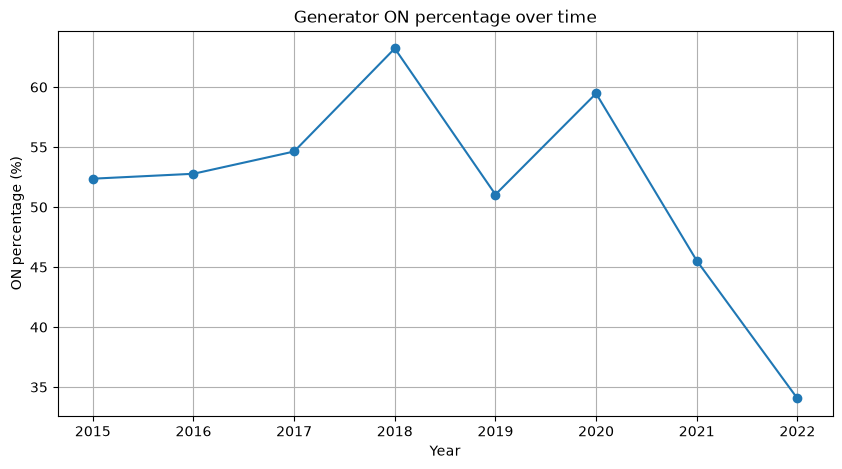

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Caricamento dataset
df = pd.read_csv(
    "../sintef_project/data/kernel/Unit_commitment_decisions.csv"
)

# Selezioniamo esclusivamente le colonne ON/OFF
target_cols = [
    col for col in df.columns
    if col.startswith("result_committed_")
]

print("Numero di casi:", len(df))
print("Numero di colonne target:", len(target_cols))

assert len(target_cols) == 14 * 168
assert df[target_cols].notna().all().all()
assert df[target_cols].isin([0, 1]).all().all()

# Creiamo un DataFrame separato per l'analisi
eda = pd.DataFrame({
    "starttime": pd.to_datetime(df["starttime"], utc=True),
    "on_rate": df[target_cols].mean(axis=1) * 100
})

eda["year"] = eda["starttime"].dt.year

# Aggregazione annuale
yearly = eda.groupby("year").agg(
    on_rate=("on_rate", "mean"),
    n_cases=("on_rate", "size")
)

display(yearly)

# Grafico
plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly["on_rate"], marker="o")

plt.xlabel("Year")
plt.ylabel("ON percentage (%)")
plt.title("Generator ON percentage over time")
plt.grid(True)
plt.show()

Grafico On e Off dei mesi degli anni dal 2020 in poi per capire che minchia è successo

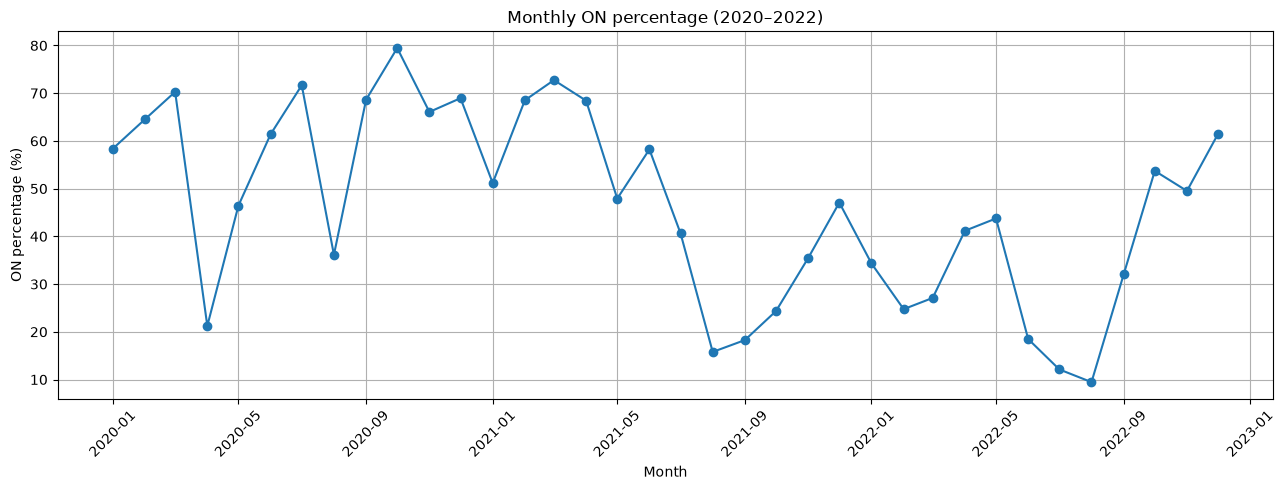

In [2]:
# Percentuale ON per mese
monthly = (
    eda.set_index("starttime")
       .resample("MS")["on_rate"]
       .mean()
)

# Visualizziamo gli ultimi tre anni
monthly_recent = monthly.loc["2020":"2022"]

plt.figure(figsize=(13, 5))

plt.plot(
    monthly_recent.index,
    monthly_recent.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("ON percentage (%)")
plt.title("Monthly ON percentage (2020–2022)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Questo grafico è molto interessante perché ci permette di capire meglio cosa sia successo tra il 2020 e il 2022. E soprattutto ci dà alcune indicazioni utili per scegliere lo split del nostro XGBoost.
1. Cosa osserviamo?
Dal grafico emergono tre aspetti.
Il 2020 presenta una forte variabilità mensile. La percentuale ON oscilla approssimativamente tra il 20% e l'80%. Questo significa che il comportamento dei generatori cambia parecchio anche all'interno dello stesso anno.
Nel 2021 si osserva un calo importante nella seconda metà dell'anno. Dopo percentuali relativamente elevate nei primi mesi, arriviamo a valori intorno al 15–25% tra agosto e ottobre.
Nel 2022 la percentuale ON rimane generalmente bassa, soprattutto durante la primavera e l'estate, ma torna a crescere sensibilmente negli ultimi mesi.
Questo significa che non stiamo osservando semplicemente un calo lineare e continuo: ci sono anche oscillazioni molto marcate.
2. Cosa significa per il nostro modello?
Dobbiamo considerare almeno due possibilità.
La prima è che esista una forte stagionalità: determinati mesi dell'anno potrebbero avere sistematicamente percentuali ON differenti.
La seconda è che ci sia stato un cambiamento nelle condizioni operative dopo il 2020, per esempio legato ai prezzi dell'energia o alle condizioni idrologiche.
Le due spiegazioni possono anche coesistere.
La cosa importante è che, se vogliamo prevedere il 2025, il nostro modello deve saper riconoscere queste condizioni attraverso le feature, non semplicemente memorizzare il comportamento degli anni precedenti.
3. Cosa farei ora per lo split?
A questo punto abbiamo abbastanza informazioni per iniziare a progettare la Walk-Forward Validation.
Ti proporrei di confrontare due strategie:
Strategia	Training	Validation
Expanding window	Tutti gli anni precedenti	Anno successivo
Sliding window	Soltanto gli ultimi 3–4 anni	Anno successivo
La differenza è importante.
Con l'expanding window, il training cresce progressivamente e mantiene tutti i dati storici.
Con la sliding window, invece, eliminiamo progressivamente gli anni più vecchi, ipotizzando che le condizioni operative recenti siano più rappresentative del futuro.
Personalmente inizierei dall'expanding window, perché utilizza più dati. Successivamente confronterei i risultati con una sliding window per verificare se i dati più vecchi aiutino davvero il modello.
Un'altra precauzione fondamentale: visto che ogni caso contiene una finestra di 168 ore e sembra esserci un caso per giorno, dovremo introdurre una separazione temporale tra training e validation per evitare sovrapposizioni.